# Human Kidney Cancer Analysis

In [1]:
import sys

import anndata as ad
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import squidpy as sq

from pathlib import Path
sys.path.insert(0, str(Path('./SpatialScope').resolve()))

import src as spatialscope
import src.utils as spatialscope_utils

In [2]:
Path('./SpatialScope').resolve()

PosixPath('/workspace/NNct-SVG/SpatialScope')

In [3]:
str(Path('./SpatialScope').resolve())

'/workspace/NNct-SVG/SpatialScope'

In [4]:
st_data_dir = Path('ST checkpoints/Human Kidney Cancer')
sc_data_dir = Path('scRNA ref checkpoints/Human Kidney Cancer')
decomp_dir = Path('spatialscope_output/Human Kidney Cancer Interface')

In [5]:
adata_decomp = sc.read(decomp_dir / 'sp_adata.h5ad')

In [6]:
adata_decomp

AnnData object with n_obs × n_vars = 2047 × 2215
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'n_counts', 'cell_count'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'estimated_be'
    uns: 'cell_locations', 'sample_colors', 'spatial'
    obsm: 'image_features', 'spatial'

In [7]:
adata_decomp.uns['cell_locations'].head()

,x,y,spot_index,cell_index,cell_nums,discrete_label,discrete_label_ct
0,7156.041045,6129.735075,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_0,13,9,RCC
1,7174.752266,6088.093656,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_1,13,1,EC
2,7180.500000,6151.666667,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_2,13,9,RCC
3,7191.066489,6103.723404,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_3,13,9,RCC
4,7221.500000,6080.000000,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_4,13,6,Myeloid


In [8]:
adata_decomp.obs

,in_tissue,array_row,array_col,sample,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,mt_frac,donor_id,region,n_counts,cell_count
spot_id,,,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,1,50,102,6800STDY12499411,4778,8.471987,14815.0,9.603463,27.046912,35.227810,44.414445,56.179548,0.099426,PD47171,g,13315.0,13
6800STDY12499411_AAACACCAATAACTGC-1,1,59,19,6800STDY12499411,1536,7.337588,2822.0,7.945555,27.250177,36.463501,46.172927,63.288448,0.105245,PD47171,g,2520.0,15
6800STDY12499411_AAACATGGTGAGAGGA-1,1,62,0,6800STDY12499411,2243,7.716015,4582.0,8.430109,28.000873,35.050196,44.107377,59.340899,0.165430,PD47171,g,3800.0,20
6800STDY12499411_AAACCGGGTAGGTACC-1,1,42,28,6800STDY12499411,2555,7.846199,4903.0,8.497807,19.620640,28.696716,38.894554,53.885376,0.044463,PD47171,g,4663.0,13
6800STDY12499411_AAACCGTTCGTCCAGG-1,1,52,42,6800STDY12499411,1277,7.153052,2113.0,7.656337,22.432560,32.465689,43.965925,63.227638,0.034548,PD47171,g,2033.0,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,1,24,64,6800STDY12499411,3235,8.082093,8386.0,9.034438,25.518722,36.358216,46.255664,59.372764,0.061770,PD47171,g,7848.0,15
6800STDY12499411_TTGTTGTGTGTCAAGA-1,1,31,77,6800STDY12499411,4374,8.383662,12266.0,9.414668,22.215881,31.664764,41.415294,54.345345,0.036116,PD47171,g,11792.0,17
6800STDY12499411_TTGTTTCACATCCAGG-1,1,58,42,6800STDY12499411,1328,7.192182,2317.0,7.748460,23.910229,34.570565,45.576176,64.264135,0.015537,PD47171,g,2275.0,14


/workspace/NNct-SVG/SpatialScope/src/utils.py:212: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  test = sc.AnnData(np.zeros(merged_df.shape), obs=merged_df)
/opt/conda/envs/SpatialScope/lib/python3.9/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


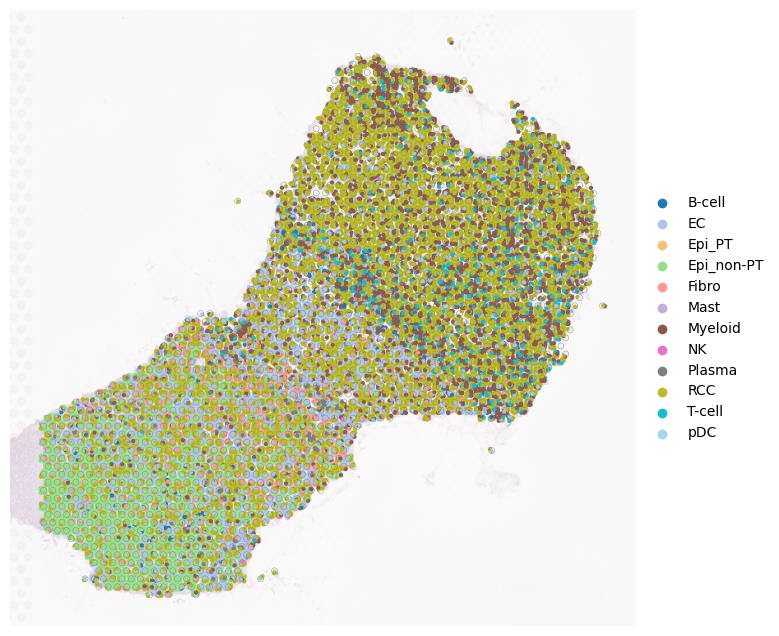

In [9]:
fig, ax = plt.subplots(1,1,figsize=(12, 8),dpi=100)
spatialscope_utils.PlotVisiumCells(adata_decomp,"discrete_label_ct",size=0.7,alpha_img=0.2,lw=0.3,ax=ax)

In [10]:
adata_sc = sc.read(sc_data_dir / 'Human Kidney Cancer.h5ad')
adata_sc    

AnnData object with n_obs × n_vars = 10813 × 15688
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'patient', 'percent.mt', 'summaryDescription', 'annotation', 'region', 'broad_type'
    var: 'SYMBOL', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'Marker'
    uns: 'annotation_colors', 'broad_type_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'region_colors', 'summaryDescription_colors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'original'
    obsp: 'connectivities', 'distances'

/opt/conda/envs/SpatialScope/lib/python3.9/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  [AnnData(sparse.csr_matrix(a.shape), obs=a.obs) for a in all_adatas],
/opt/conda/envs/SpatialScope/lib/python3.9/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


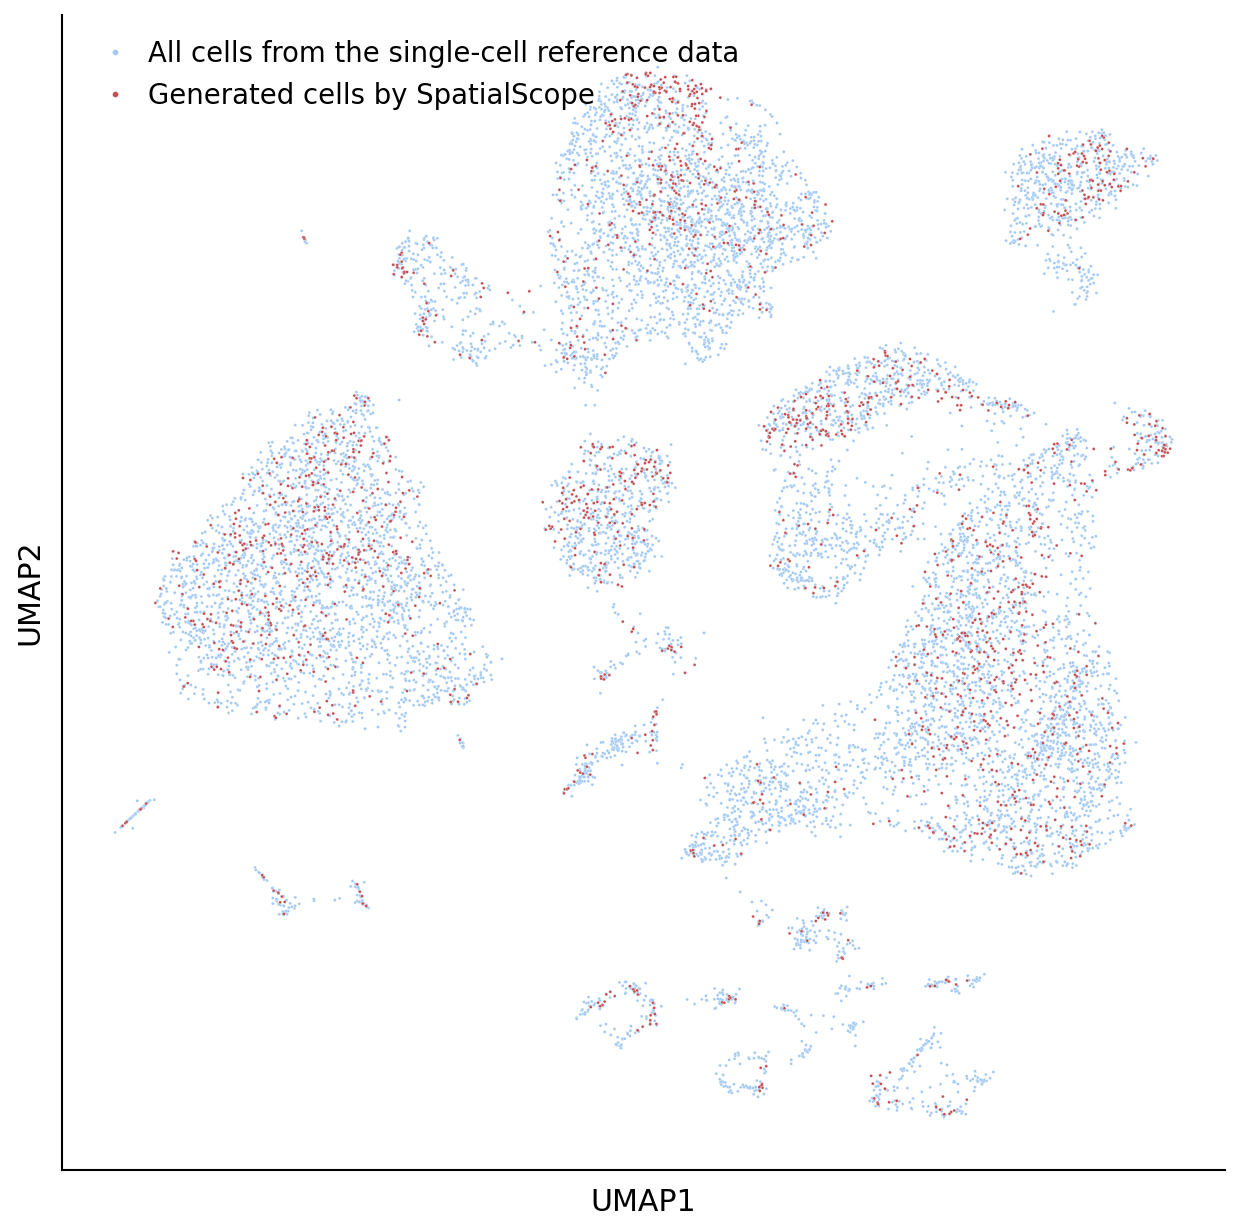

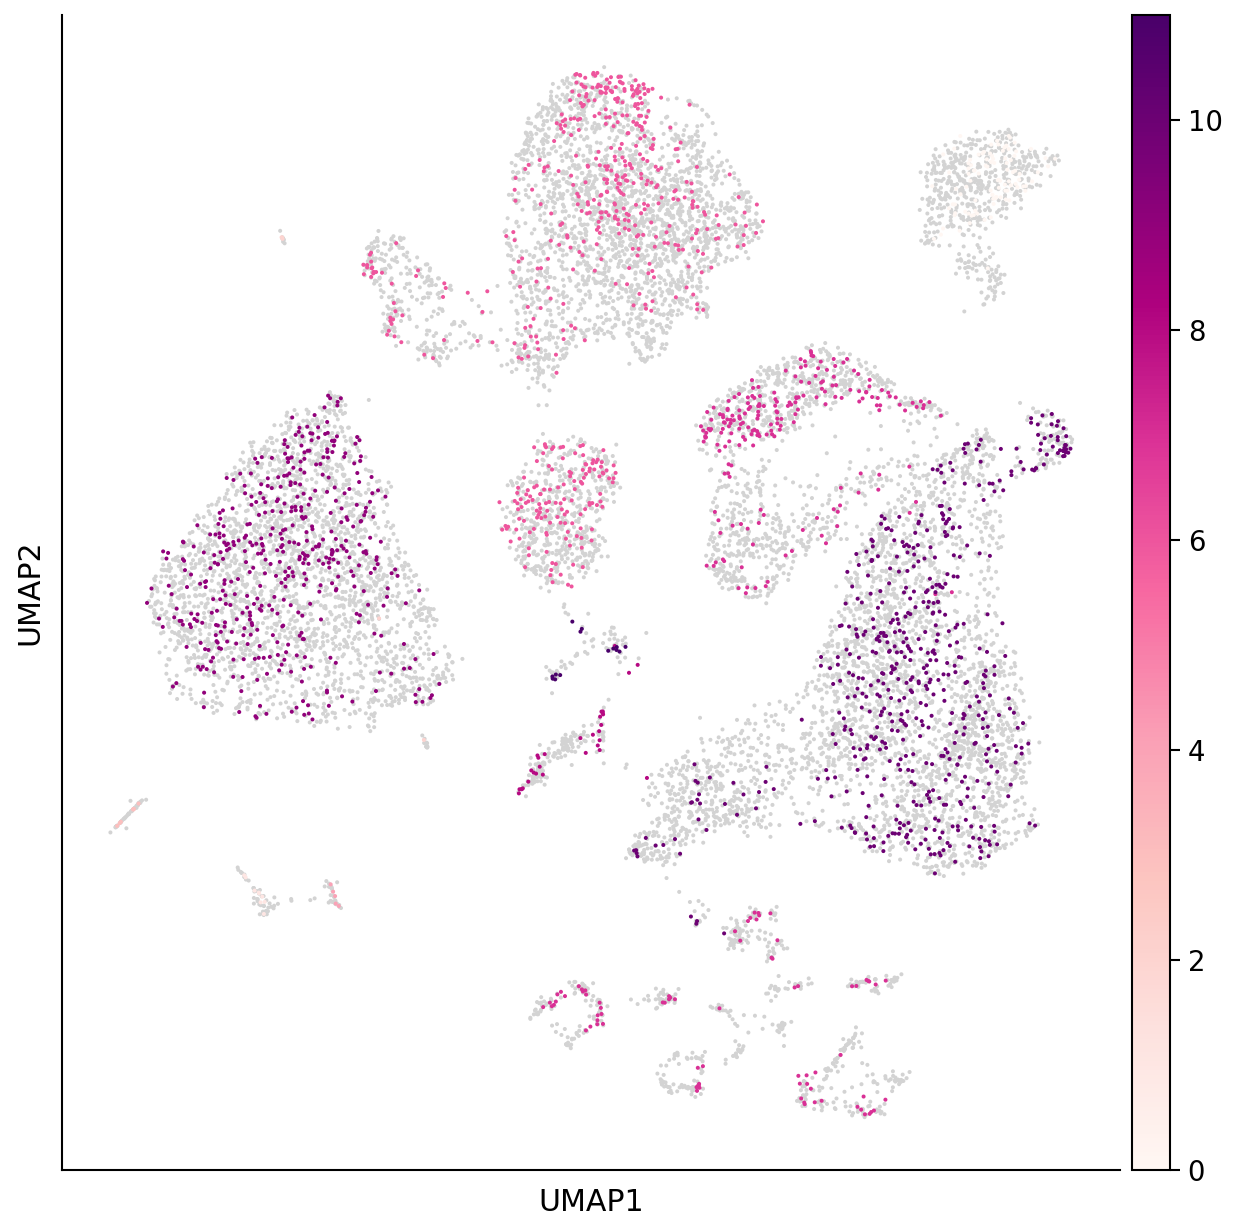

In [11]:
sampled_cells = sc.read(sc_data_dir / 'model_10000.h5ad')
cell_type_key = 'cell type'
sns.set_context('paper', font_scale=1.5)
adata_sc_all = spatialscope_utils.PlotSampledData(sampled_cells, adata_sc, cell_type_key)

In [12]:
adata_decomp.uns['cell_locations']

,x,y,spot_index,cell_index,cell_nums,discrete_label,discrete_label_ct
0,7156.041045,6129.735075,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_0,13,9,RCC
1,7174.752266,6088.093656,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_1,13,1,EC
2,7180.500000,6151.666667,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_2,13,9,RCC
3,7191.066489,6103.723404,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_3,13,9,RCC
4,7221.500000,6080.000000,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_4,13,6,Myeloid
...,...,...,...,...,...,...,...
30486,2926.909091,5656.954545,6800STDY12499411_TTGTTTCCATACAACT-1,6800STDY12499411_TTGTTTCCATACAACT-1_12,17,1,EC
30487,2977.204301,5641.010753,6800STDY12499411_TTGTTTCCATACAACT-1,6800STDY12499411_TTGTTTCCATACAACT-1_13,17,9,RCC
30488,2952.430108,5611.731183,6800STDY12499411_TTGTTTCCATACAACT-1,6800STDY12499411_TTGTTTCCATACAACT-1_14,17,6,Myeloid
30489,2972.000000,5586.000000,6800STDY12499411_TTGTTTCCATACAACT-1,6800STDY12499411_TTGTTTCCATACAACT-1_15,17,9,RCC


In [13]:
adata_decomp

AnnData object with n_obs × n_vars = 2047 × 2215
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'n_counts', 'cell_count'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'estimated_be'
    uns: 'cell_locations', 'sample_colors', 'spatial'
    obsm: 'image_features', 'spatial'

In [14]:
adata_st = sc.read(st_data_dir / 'Human Kidney Cancer Interface.h5ad')
adata_st

AnnData object with n_obs × n_vars = 2048 × 15413
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411'
    uns: 'sample_colors', 'spatial'
    obsm: 'spatial'

The features of adata_decomp is based on the HVGs in the reference scRNA dataset, and not on the original ST dataset. For analysis, we will only consider the features common to the Spatial dataset and scRNA Reference dataset.

In [15]:
adata_st.n_vars

15413

In [16]:
adata_decomp.n_vars

2215

In [17]:
decomp_st_common_genes = adata_decomp.var.index.intersection(adata_st.var.index)
decomp_st_common_genes

Index(['ENSG00000187583', 'ENSG00000188290', 'ENSG00000187608',
       'ENSG00000188157', 'ENSG00000186891', 'ENSG00000186827',
       'ENSG00000162572', 'ENSG00000162576', 'ENSG00000242485',
       'ENSG00000179403',
       ...
       'ENSG00000029993', 'ENSG00000147400', 'ENSG00000183837',
       'ENSG00000130822', 'ENSG00000130821', 'ENSG00000180879',
       'ENSG00000196924', 'ENSG00000147403', 'ENSG00000185010',
       'ENSG00000214827'],
      dtype='object', name='ENSEMBL', length=2215)

In [18]:
adata_decomp_common = adata_decomp[:, decomp_st_common_genes]
adata_st_common = adata_st[:, decomp_st_common_genes]
adata_decomp_common, adata_st_common

(View of AnnData object with n_obs × n_vars = 2047 × 2215
     obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'n_counts', 'cell_count'
     var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'estimated_be'
     uns: 'cell_locations', 'sample_colors', 'spatial'
     obsm: 'image_features', 'spatial',
 View of AnnData object with n_obs × n_vars = 2048 × 2215
     obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes'

In [19]:
adata_st_common_df = adata_st_common.to_df()
adata_st_common_df

ENSEMBL,ENSG00000187583,ENSG00000188290,ENSG00000187608,ENSG00000188157,ENSG00000186891,ENSG00000186827,ENSG00000162572,ENSG00000162576,ENSG00000242485,ENSG00000179403,...,ENSG00000029993,ENSG00000147400,ENSG00000183837,ENSG00000130822,ENSG00000130821,ENSG00000180879,ENSG00000196924,ENSG00000147403,ENSG00000185010,ENSG00000214827
spot_id,,,,,,,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,0.0,5.0,2.0,4.0,0.0,0.0,0.0,1.0,0.0,2.0,...,0.0,0.0,0.0,0.0,2.0,6.0,9.0,65.0,0.0,0.0
6800STDY12499411_AAACACCAATAACTGC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,9.0,0.0,0.0
6800STDY12499411_AAACATGGTGAGAGGA-1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,10.0,0.0,0.0
6800STDY12499411_AAACCGGGTAGGTACC-1,0.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,1.0,6.0,16.0,0.0,0.0
6800STDY12499411_AAACCGTTCGTCCAGG-1,0.0,0.0,1.0,2.0,1.0,0.0,0.0,0.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,4.0,10.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,0.0,1.0,1.0,4.0,0.0,0.0,0.0,0.0,2.0,2.0,...,0.0,0.0,0.0,0.0,1.0,3.0,5.0,53.0,0.0,0.0
6800STDY12499411_TTGTTGTGTGTCAAGA-1,1.0,3.0,3.0,2.0,0.0,1.0,1.0,0.0,1.0,4.0,...,0.0,1.0,0.0,0.0,0.0,11.0,8.0,57.0,1.0,0.0
6800STDY12499411_TTGTTTCACATCCAGG-1,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,2.0,1.0,20.0,1.0,0.0


In [20]:
adata_decomp_common_df = adata_decomp_common.to_df()
adata_decomp_common_df

ENSEMBL,ENSG00000187583,ENSG00000188290,ENSG00000187608,ENSG00000188157,ENSG00000186891,ENSG00000186827,ENSG00000162572,ENSG00000162576,ENSG00000242485,ENSG00000179403,...,ENSG00000029993,ENSG00000147400,ENSG00000183837,ENSG00000130822,ENSG00000130821,ENSG00000180879,ENSG00000196924,ENSG00000147403,ENSG00000185010,ENSG00000214827
spot_id,,,,,,,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,0.0,5.0,2.0,4.0,0.0,0.0,0.0,1.0,0.0,2.0,...,0.0,0.0,0.0,0.0,2.0,6.0,9.0,65.0,0.0,0.0
6800STDY12499411_AAACACCAATAACTGC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,9.0,0.0,0.0
6800STDY12499411_AAACATGGTGAGAGGA-1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,10.0,0.0,0.0
6800STDY12499411_AAACCGGGTAGGTACC-1,0.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,1.0,6.0,16.0,0.0,0.0
6800STDY12499411_AAACCGTTCGTCCAGG-1,0.0,0.0,1.0,2.0,1.0,0.0,0.0,0.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,4.0,10.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,0.0,1.0,1.0,4.0,0.0,0.0,0.0,0.0,2.0,2.0,...,0.0,0.0,0.0,0.0,1.0,3.0,5.0,53.0,0.0,0.0
6800STDY12499411_TTGTTGTGTGTCAAGA-1,1.0,3.0,3.0,2.0,0.0,1.0,1.0,0.0,1.0,4.0,...,0.0,1.0,0.0,0.0,0.0,11.0,8.0,57.0,1.0,0.0
6800STDY12499411_TTGTTTCACATCCAGG-1,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,2.0,1.0,20.0,1.0,0.0


In [21]:
adata_st_common_df_aligned, adata_decomp_common_df_aligned = adata_st_common_df.align(adata_decomp_common_df, join="inner")
adata_st_common_df_aligned

ENSEMBL,ENSG00000187583,ENSG00000188290,ENSG00000187608,ENSG00000188157,ENSG00000186891,ENSG00000186827,ENSG00000162572,ENSG00000162576,ENSG00000242485,ENSG00000179403,...,ENSG00000029993,ENSG00000147400,ENSG00000183837,ENSG00000130822,ENSG00000130821,ENSG00000180879,ENSG00000196924,ENSG00000147403,ENSG00000185010,ENSG00000214827
spot_id,,,,,,,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,0.0,5.0,2.0,4.0,0.0,0.0,0.0,1.0,0.0,2.0,...,0.0,0.0,0.0,0.0,2.0,6.0,9.0,65.0,0.0,0.0
6800STDY12499411_AAACACCAATAACTGC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,9.0,0.0,0.0
6800STDY12499411_AAACATGGTGAGAGGA-1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,10.0,0.0,0.0
6800STDY12499411_AAACCGGGTAGGTACC-1,0.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,1.0,6.0,16.0,0.0,0.0
6800STDY12499411_AAACCGTTCGTCCAGG-1,0.0,0.0,1.0,2.0,1.0,0.0,0.0,0.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,4.0,10.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,0.0,1.0,1.0,4.0,0.0,0.0,0.0,0.0,2.0,2.0,...,0.0,0.0,0.0,0.0,1.0,3.0,5.0,53.0,0.0,0.0
6800STDY12499411_TTGTTGTGTGTCAAGA-1,1.0,3.0,3.0,2.0,0.0,1.0,1.0,0.0,1.0,4.0,...,0.0,1.0,0.0,0.0,0.0,11.0,8.0,57.0,1.0,0.0
6800STDY12499411_TTGTTTCACATCCAGG-1,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,2.0,1.0,20.0,1.0,0.0


In [22]:
adata_decomp_common_df_aligned

ENSEMBL,ENSG00000187583,ENSG00000188290,ENSG00000187608,ENSG00000188157,ENSG00000186891,ENSG00000186827,ENSG00000162572,ENSG00000162576,ENSG00000242485,ENSG00000179403,...,ENSG00000029993,ENSG00000147400,ENSG00000183837,ENSG00000130822,ENSG00000130821,ENSG00000180879,ENSG00000196924,ENSG00000147403,ENSG00000185010,ENSG00000214827
spot_id,,,,,,,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,0.0,5.0,2.0,4.0,0.0,0.0,0.0,1.0,0.0,2.0,...,0.0,0.0,0.0,0.0,2.0,6.0,9.0,65.0,0.0,0.0
6800STDY12499411_AAACACCAATAACTGC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,9.0,0.0,0.0
6800STDY12499411_AAACATGGTGAGAGGA-1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,10.0,0.0,0.0
6800STDY12499411_AAACCGGGTAGGTACC-1,0.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,1.0,6.0,16.0,0.0,0.0
6800STDY12499411_AAACCGTTCGTCCAGG-1,0.0,0.0,1.0,2.0,1.0,0.0,0.0,0.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,4.0,10.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,0.0,1.0,1.0,4.0,0.0,0.0,0.0,0.0,2.0,2.0,...,0.0,0.0,0.0,0.0,1.0,3.0,5.0,53.0,0.0,0.0
6800STDY12499411_TTGTTGTGTGTCAAGA-1,1.0,3.0,3.0,2.0,0.0,1.0,1.0,0.0,1.0,4.0,...,0.0,1.0,0.0,0.0,0.0,11.0,8.0,57.0,1.0,0.0
6800STDY12499411_TTGTTTCACATCCAGG-1,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,2.0,1.0,20.0,1.0,0.0


In [23]:
(adata_st_common_df_aligned == adata_decomp_common_df_aligned).all().all()

True

In [24]:
adata_decomp.uns['cell_locations']

,x,y,spot_index,cell_index,cell_nums,discrete_label,discrete_label_ct
0,7156.041045,6129.735075,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_0,13,9,RCC
1,7174.752266,6088.093656,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_1,13,1,EC
2,7180.500000,6151.666667,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_2,13,9,RCC
3,7191.066489,6103.723404,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_3,13,9,RCC
4,7221.500000,6080.000000,6800STDY12499411_AAACAAGTATCTCCCA-1,6800STDY12499411_AAACAAGTATCTCCCA-1_4,13,6,Myeloid
...,...,...,...,...,...,...,...
30486,2926.909091,5656.954545,6800STDY12499411_TTGTTTCCATACAACT-1,6800STDY12499411_TTGTTTCCATACAACT-1_12,17,1,EC
30487,2977.204301,5641.010753,6800STDY12499411_TTGTTTCCATACAACT-1,6800STDY12499411_TTGTTTCCATACAACT-1_13,17,9,RCC
30488,2952.430108,5611.731183,6800STDY12499411_TTGTTTCCATACAACT-1,6800STDY12499411_TTGTTTCCATACAACT-1_14,17,6,Myeloid
30489,2972.000000,5586.000000,6800STDY12499411_TTGTTTCCATACAACT-1,6800STDY12499411_TTGTTTCCATACAACT-1_15,17,9,RCC


In [25]:
adata_decomp_common_df_aligned

ENSEMBL,ENSG00000187583,ENSG00000188290,ENSG00000187608,ENSG00000188157,ENSG00000186891,ENSG00000186827,ENSG00000162572,ENSG00000162576,ENSG00000242485,ENSG00000179403,...,ENSG00000029993,ENSG00000147400,ENSG00000183837,ENSG00000130822,ENSG00000130821,ENSG00000180879,ENSG00000196924,ENSG00000147403,ENSG00000185010,ENSG00000214827
spot_id,,,,,,,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,0.0,5.0,2.0,4.0,0.0,0.0,0.0,1.0,0.0,2.0,...,0.0,0.0,0.0,0.0,2.0,6.0,9.0,65.0,0.0,0.0
6800STDY12499411_AAACACCAATAACTGC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,9.0,0.0,0.0
6800STDY12499411_AAACATGGTGAGAGGA-1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,10.0,0.0,0.0
6800STDY12499411_AAACCGGGTAGGTACC-1,0.0,0.0,0.0,2.0,0.0,0.0,0.0,2.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,1.0,6.0,16.0,0.0,0.0
6800STDY12499411_AAACCGTTCGTCCAGG-1,0.0,0.0,1.0,2.0,1.0,0.0,0.0,0.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,4.0,10.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,0.0,1.0,1.0,4.0,0.0,0.0,0.0,0.0,2.0,2.0,...,0.0,0.0,0.0,0.0,1.0,3.0,5.0,53.0,0.0,0.0
6800STDY12499411_TTGTTGTGTGTCAAGA-1,1.0,3.0,3.0,2.0,0.0,1.0,1.0,0.0,1.0,4.0,...,0.0,1.0,0.0,0.0,0.0,11.0,8.0,57.0,1.0,0.0
6800STDY12499411_TTGTTTCACATCCAGG-1,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,2.0,1.0,20.0,1.0,0.0


In [26]:
batch_start_end = [(0, 1024), (1024,2047)]
adata_generated_batch_files = [decomp_dir / f'generated_cells_spot{start}_{end}.h5ad' for start,end in batch_start_end]
adata_generated_batches = [sc.read(adata_generated_batch_file) for adata_generated_batch_file in adata_generated_batch_files]
adata_generated = ad.concat(adata_generated_batches, label="batch")
adata_generated

AnnData object with n_obs × n_vars = 30491 × 3323
    obs: 'x', 'y', 'spot_index', 'cell_index', 'cell_nums', 'discrete_label', 'discrete_label_ct', 'batch'

In [27]:
adata_generated_common = adata_generated[:, decomp_st_common_genes]
adata_generated_common

View of AnnData object with n_obs × n_vars = 30491 × 2215
    obs: 'x', 'y', 'spot_index', 'cell_index', 'cell_nums', 'discrete_label', 'discrete_label_ct', 'batch'

In [28]:
adata_generated_common_df = adata_generated_common.to_df()
adata_generated_common_df

ENSEMBL,ENSG00000187583,ENSG00000188290,ENSG00000187608,ENSG00000188157,ENSG00000186891,ENSG00000186827,ENSG00000162572,ENSG00000162576,ENSG00000242485,ENSG00000179403,...,ENSG00000029993,ENSG00000147400,ENSG00000183837,ENSG00000130822,ENSG00000130821,ENSG00000180879,ENSG00000196924,ENSG00000147403,ENSG00000185010,ENSG00000214827
0,0.002447,0.000000,0.481074,0.112566,0.000423,0.000120,0.000501,0.000920,0.000000,0.001609,...,0.000000,0.000000,0.000505,0.000570,0.000565,0.291871,0.000444,9.813538,0.000000,0.000152
1,0.000257,0.002664,0.001850,0.002539,0.000678,0.001277,0.000404,0.000109,0.147426,0.151067,...,0.148262,0.000000,0.000163,0.000551,0.000828,0.477678,0.092030,0.846797,0.239370,0.000673
2,0.000000,0.086914,0.000613,0.088934,0.000000,0.000442,0.000684,0.000679,0.084818,0.001066,...,0.000305,0.084637,0.001189,0.000573,0.000969,1.087108,0.195750,9.099983,0.000000,0.000678
3,0.000000,0.072804,0.001344,0.000508,0.000000,0.000000,0.001061,0.001010,0.000000,0.073508,...,0.000097,0.071414,0.000533,0.000491,0.000930,0.071601,0.303748,8.781310,0.000000,0.000075
4,0.000820,0.000000,0.047177,0.001702,0.000400,0.000141,0.000268,0.000364,0.000000,0.001118,...,0.000000,0.000000,0.000251,0.000282,0.000822,0.263188,0.000477,2.267647,0.000000,0.000212
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30486,0.000000,0.000000,0.159414,0.071967,0.000000,0.056414,0.000000,0.000000,0.088464,0.677462,...,0.000000,0.238641,0.000000,0.000000,0.000000,0.298294,0.162937,3.816484,0.072889,0.000000
30487,0.000000,0.116014,0.000000,0.103100,0.000000,0.000000,0.000000,0.000000,0.000000,0.104835,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.101696,0.795660,10.655735,0.000000,0.000000
30488,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.406905,0.173583,4.715415,0.000000,0.000000
30489,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.262386,0.484995,15.810009,0.000000,0.000000


In [29]:
adata_recon = adata_generated_common_df.groupby(adata_generated_common.obs["spot_index"]).sum().round()
adata_recon

ENSEMBL,ENSG00000187583,ENSG00000188290,ENSG00000187608,ENSG00000188157,ENSG00000186891,ENSG00000186827,ENSG00000162572,ENSG00000162576,ENSG00000242485,ENSG00000179403,...,ENSG00000029993,ENSG00000147400,ENSG00000183837,ENSG00000130822,ENSG00000130821,ENSG00000180879,ENSG00000196924,ENSG00000147403,ENSG00000185010,ENSG00000214827
spot_index,,,,,,,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,0.0,2.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,5.0,2.0,80.0,0.0,0.0
6800STDY12499411_AAACACCAATAACTGC-1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,10.0,2.0,69.0,1.0,0.0
6800STDY12499411_AAACATGGTGAGAGGA-1,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,5.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,2.0,78.0,0.0,0.0
6800STDY12499411_AAACCGGGTAGGTACC-1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,3.0,1.0,...,0.0,1.0,0.0,0.0,0.0,3.0,3.0,67.0,0.0,0.0
6800STDY12499411_AAACCGTTCGTCCAGG-1,0.0,0.0,5.0,4.0,1.0,0.0,0.0,0.0,18.0,0.0,...,0.0,1.0,0.0,0.0,0.0,2.0,7.0,123.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,3.0,1.0,...,0.0,0.0,0.0,0.0,0.0,5.0,2.0,116.0,1.0,0.0
6800STDY12499411_TTGTTGTGTGTCAAGA-1,0.0,2.0,2.0,1.0,0.0,0.0,0.0,0.0,1.0,2.0,...,0.0,1.0,0.0,0.0,0.0,13.0,2.0,99.0,2.0,0.0
6800STDY12499411_TTGTTTCACATCCAGG-1,0.0,0.0,3.0,1.0,0.0,0.0,0.0,0.0,6.0,2.0,...,0.0,1.0,0.0,0.0,0.0,11.0,1.0,165.0,6.0,0.0


In [30]:
adata_recon2 = adata_generated_common_df.round().groupby(adata_generated_common.obs["spot_index"]).sum()
adata_recon2

ENSEMBL,ENSG00000187583,ENSG00000188290,ENSG00000187608,ENSG00000188157,ENSG00000186891,ENSG00000186827,ENSG00000162572,ENSG00000162576,ENSG00000242485,ENSG00000179403,...,ENSG00000029993,ENSG00000147400,ENSG00000183837,ENSG00000130822,ENSG00000130821,ENSG00000180879,ENSG00000196924,ENSG00000147403,ENSG00000185010,ENSG00000214827
spot_index,,,,,,,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,3.0,1.0,81.0,0.0,0.0
6800STDY12499411_AAACACCAATAACTGC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,10.0,1.0,68.0,0.0,0.0
6800STDY12499411_AAACATGGTGAGAGGA-1,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,3.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,0.0,79.0,0.0,0.0
6800STDY12499411_AAACCGGGTAGGTACC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,67.0,0.0,0.0
6800STDY12499411_AAACCGTTCGTCCAGG-1,0.0,0.0,4.0,2.0,2.0,0.0,0.0,0.0,18.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,8.0,123.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,117.0,0.0,0.0
6800STDY12499411_TTGTTGTGTGTCAAGA-1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,12.0,1.0,101.0,1.0,0.0
6800STDY12499411_TTGTTTCACATCCAGG-1,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,5.0,2.0,...,0.0,0.0,0.0,0.0,0.0,9.0,0.0,167.0,5.0,0.0


In [31]:
recon_mean_error = np.sqrt(np.square(adata_recon - adata_decomp_common_df_aligned)).mean().mean()
recon_max_error = np.sqrt(np.square(adata_recon - adata_decomp_common_df_aligned)).max().max()
recon_mean_error, recon_max_error

(1.9335673, 2021.0)

In [32]:
recon2_mean_error = np.sqrt(np.square(adata_recon2 - adata_decomp_common_df_aligned)).mean().mean()
recon2_max_error = np.sqrt(np.square(adata_recon2 - adata_decomp_common_df_aligned)).max().max()
recon2_mean_error, recon2_max_error

(1.8571752, 2025.0)

In [ ]:
adata_st_common_df = adata_st_common.to_df()
adata_st_common_df

In [ ]:
adata_recon_common_df.max().max()

In [ ]:
adata_st_common_df.max().max()

In [ ]:
adata_st_common_df.index = adata_st_common_df.index.astype(str)
adata_st_common_df.index

In [ ]:
adata_recon_common_df.index = adata_recon_common_df.index.astype(str)
adata_recon_common_df.index

In [ ]:
adata_st_common_df_aligned, adata_recon_common_df_aligned = adata_st_common_df.align(adata_recon_common_df, join="inner")
adata_st_common_df_aligned

In [ ]:
mse = ((adata_st_common_df_aligned - adata_recon_common_df_aligned)**2).values.mean()
mse

In [ ]:
per_row_mse = ((adata_st_common_df_aligned - adata_recon_common_df_aligned)**2).values.mean(axis=1)
per_row_mse

In [ ]:
adata_st_common.obs

In [ ]:
adata_decomp.var.index.equals(adata_sc.var[adata_sc.var['highly_variable']].index)

In [ ]:
adata_decomp.var.index.intersection(adata_st.var.index)

In [ ]:
adata_decomp.var.index.intersection(adata_sc.var.index)

In [ ]:
adata_st.var.index.intersection(adata_sc.var.index)

In [ ]:
adata_st = adata_st[:, adata_decomp.var.index]
adata_st

In [ ]:
adata_sc.var

In [ ]:
adata_sc.var['Marker'].equals(adata_sc.var['highly_variable'])

In [ ]:
sel_genes = adata_sc.var.index[adata_sc.var['Marker']]
adata_st[:, adata_st.var.index.isin(sel_genes)]

In [ ]:
str(71)